# **VAE and Diffusion Models on MNIST and Fashion-MNIST**

**Stefano Meza Anzules**

## Introduction

This notebook explores the MNIST and Fashion-MNIST datasets used throughout the project. It checks the saved training and validation splits, examines class balance and pixel distributions, and illustrates how Gaussian noise is added in the forward diffusion process. No models are trained here.

## 1. Setup


In [2]:
from pathlib import Path
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torchvision.datasets import MNIST, FashionMNIST
from IPython.display import display

SEED = 111
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Locate the repository from either the root or a folder inside it.
cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, *cwd.parents]
             if (p / "scripts/prepare_data.py").is_file()
             and (p / "data").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the vae-diffusion repository.")

DATA_DIR = ROOT / "data/raw"
SPLIT_DIR = ROOT / "data/splits"
FIGURE_DIR = ROOT / "results/figures"
METRIC_DIR = ROOT / "results/metrics"
SAVE_RESULTS = True  # Reruns replace this notebook's figures and CSV tables.
if SAVE_RESULTS:
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    METRIC_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

def show_figure(fig, filename):
    if SAVE_RESULTS:
        fig.savefig(FIGURE_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("Project:", ROOT)



Project: /home/stefano98/projects/vae-diffusion


## 2. Load the datasets and saved splits

The saved indices refer to the official training partition (`train=True`). Each dataset has 50,000 training and 10,000 validation examples. The official 10,000-image test partition remains separate.

The plots below use training images. Test-set sizes are read from the preparation metadata; test images are not loaded here.


In [3]:
datasets = {}
splits = {}
metadata = {}

for name, dataset_class in {"mnist": MNIST, "fashion_mnist": FashionMNIST}.items():
    split_path = SPLIT_DIR / f"{name}_seed{SEED}.npz"
    metadata_path = split_path.with_suffix(".json")
    if not split_path.exists() or not metadata_path.exists():
        raise FileNotFoundError("Run python scripts/prepare_data.py from the project root first.")

    datasets[name] = dataset_class(root=DATA_DIR, train=True, download=False)
    with np.load(split_path, allow_pickle=False) as saved:
        splits[name] = {key: saved[key].copy() for key in ["train_idx", "val_idx"]}
    metadata[name] = json.loads(metadata_path.read_text())

class_names = {
    "mnist": [str(i) for i in range(10)],
    "fashion_mnist": list(datasets["fashion_mnist"].classes),
}


In [4]:
summary_rows = []
for name, dataset in datasets.items():
    train_idx = splits[name]["train_idx"]
    val_idx = splits[name]["val_idx"]
    info = metadata[name]
    all_idx = np.concatenate([train_idx, val_idx])

    assert train_idx.ndim == val_idx.ndim == 1
    assert np.issubdtype(train_idx.dtype, np.integer)
    assert np.issubdtype(val_idx.dtype, np.integer)
    assert len(train_idx) == info["train_size"] == 50000
    assert len(val_idx) == info["validation_size"] == 10000
    assert info["seed"] == SEED and info["dataset"] == name
    assert len(np.intersect1d(train_idx, val_idx)) == 0
    assert np.array_equal(np.sort(all_idx), np.arange(len(dataset)))
    assert tuple(dataset.data.shape[1:]) == (28, 28)
    assert dataset.data.dtype == torch.uint8
    labels = dataset.targets.numpy()
    assert np.array_equal(np.unique(labels), np.arange(10))
    assert np.bincount(labels[train_idx], minlength=10).tolist() == info["train_class_counts"]
    assert np.bincount(labels[val_idx], minlength=10).tolist() == info["validation_class_counts"]

    summary_rows.append({
        "dataset": name, "train": len(train_idx), "validation": len(val_idx),
        "test (metadata)": info["test_size"], "image_shape": "28 x 28",
        "raw_dtype": str(dataset.data.dtype), "seed": info["seed"],
    })

summary = pd.DataFrame(summary_rows).set_index("dataset")
display(summary)
print("Split checks passed: no overlap, no repeated indices, and complete training-partition coverage.")
if SAVE_RESULTS:
    summary.to_csv(METRIC_DIR / "data_summary.csv")


,train,validation,test (metadata),image_shape,raw_dtype,seed
dataset,,,,,,
mnist,50000,10000,10000,28 x 28,torch.uint8,111
fashion_mnist,50000,10000,10000,28 x 28,torch.uint8,111


Split checks passed: no overlap, no repeated indices, and complete training-partition coverage.


## 3. Examples from each class

Five examples per class are drawn from the training split. Labels are only used to arrange the plots; the first models will be unconditional.


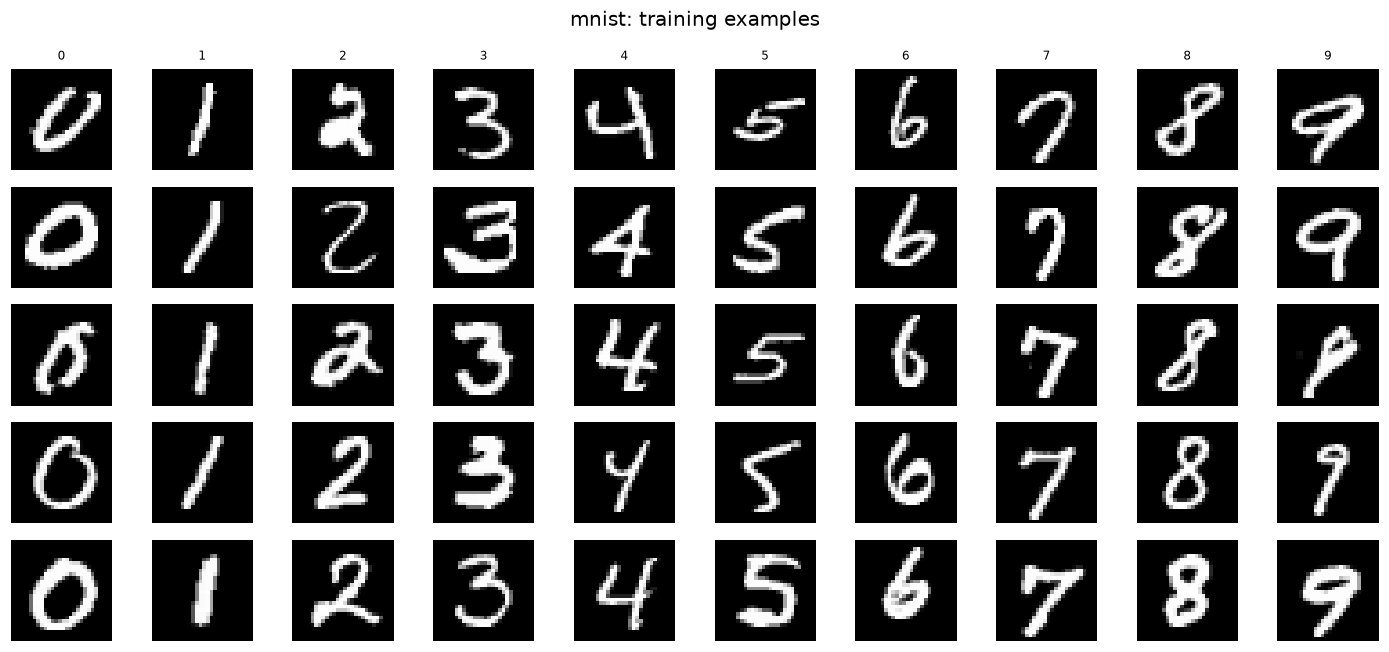

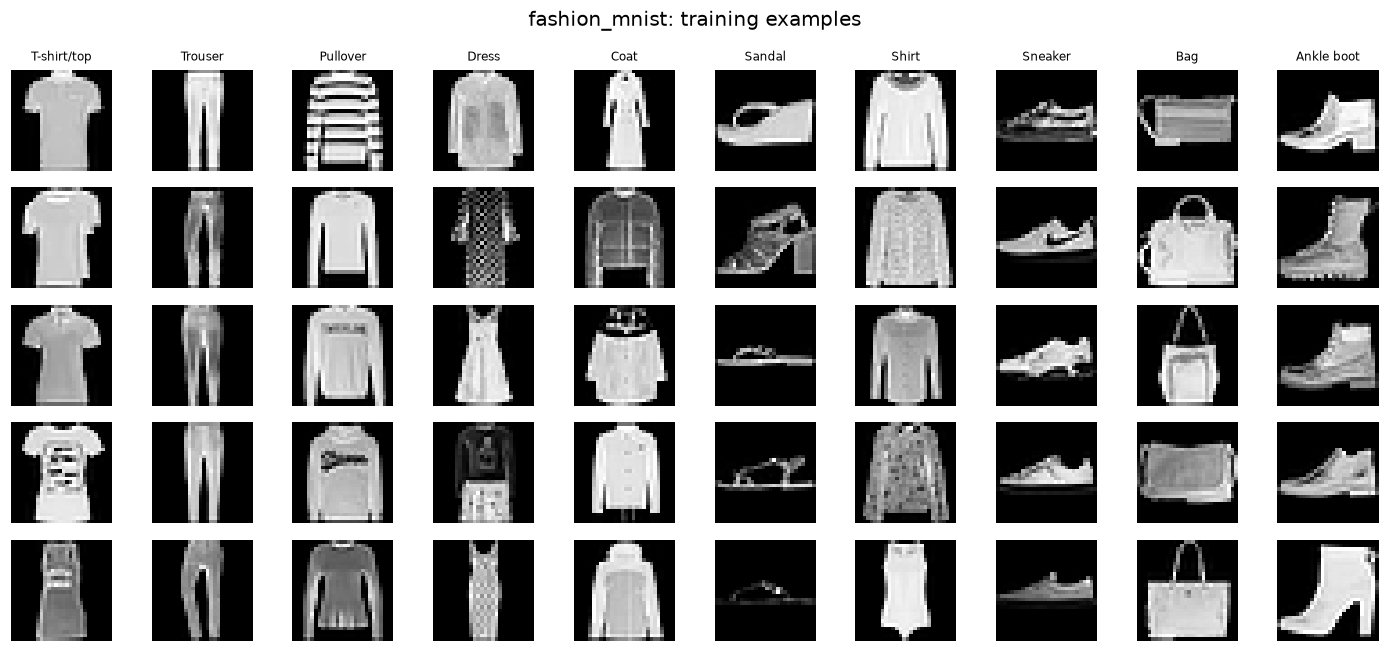

In [6]:
rng = np.random.default_rng(SEED)
example_indices = {}

for name, dataset in datasets.items():
    labels = dataset.targets.numpy()
    train_idx = splits[name]["train_idx"]
    selected = []
    fig, axes = plt.subplots(5, 10, figsize=(13, 6))
    for label in range(10):
        candidates = train_idx[labels[train_idx] == label]
        chosen = rng.choice(candidates, size=5, replace=False)
        selected.append(chosen)
        for row, idx in enumerate(chosen):
            axes[row, label].imshow(dataset.data[int(idx)].numpy(), cmap="gray", vmin=0, vmax=255)
            axes[row, label].axis("off")
        axes[0, label].set_title(class_names[name][label], fontsize=8)
    example_indices[name] = np.array(selected)
    fig.suptitle(f"{name}: training examples", fontsize=13)
    fig.tight_layout()
    show_figure(fig, f"{name}_training_examples.png")


## 4. Class balance

The split is stratified, so training and validation proportions should be similar. This preserves the dataset's existing class balance; it does not force every class to have the same number of images.


split                            train  validation
dataset       label class                         
fashion_mnist 0     T-shirt/top   5000        1000
              1     Trouser       5000        1000
              2     Pullover      5000        1000
              3     Dress         5000        1000
              4     Coat          5000        1000
              5     Sandal        5000        1000
              6     Shirt         5000        1000
              7     Sneaker       5000        1000
              8     Bag           5000        1000
              9     Ankle boot    5000        1000
mnist         0     0             4936         987
              1     1             5618        1124
              2     2             4965         993
              3     3             5109        1022
              4     4             4868         974
              5     5             4517         904
              6     6             4932         986
              7     7             5221        1044
              8     8             4876         975
              9     9             4958         991

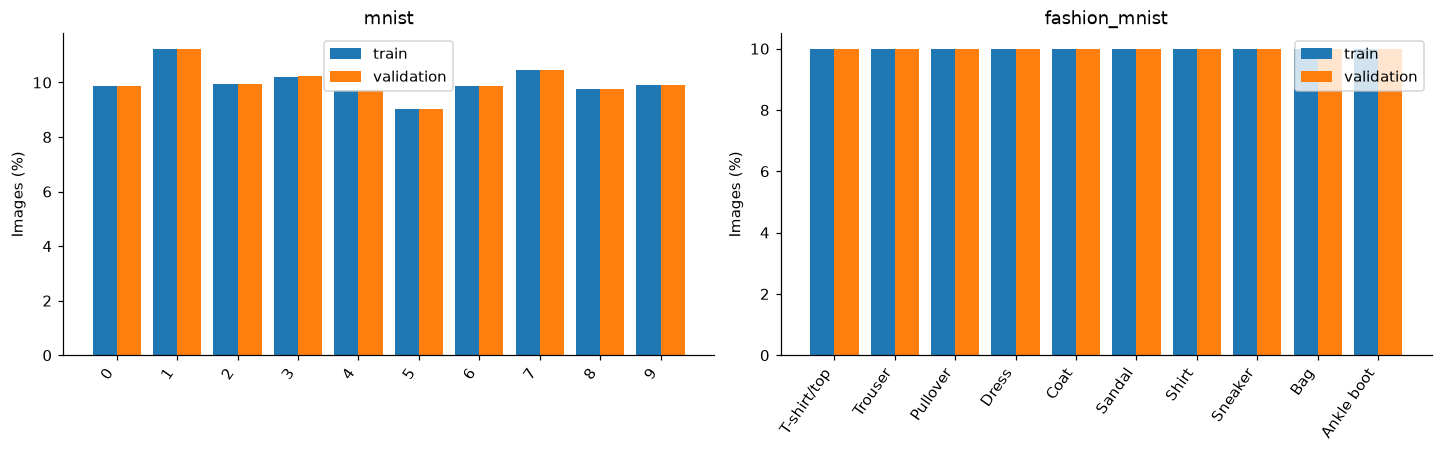

In [7]:
count_rows = []
for name, dataset in datasets.items():
    labels = dataset.targets.numpy()
    for split_name, index_key in [("train", "train_idx"), ("validation", "val_idx")]:
        indices = splits[name][index_key]
        counts = np.bincount(labels[indices], minlength=10)
        for label, count in enumerate(counts):
            count_rows.append({"dataset": name, "split": split_name,
                               "label": label, "class": class_names[name][label],
                               "count": int(count), "proportion": count / len(indices)})

class_counts = pd.DataFrame(count_rows)
display(class_counts.pivot(index=["dataset", "label", "class"], columns="split", values="count"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
for ax, name in zip(axes, datasets):
    table = class_counts[class_counts["dataset"] == name]
    positions = np.arange(10)
    for offset, split_name in [(-0.2, "train"), (0.2, "validation")]:
        values = table[table["split"] == split_name].sort_values("label")["proportion"]
        ax.bar(positions + offset, values * 100, width=0.4, label=split_name)
    ax.set_xticks(positions, class_names[name], rotation=55, ha="right")
    ax.set_title(name)
    ax.set_ylabel("Images (%)")
    ax.legend()
show_figure(fig, "class_balance.png")
if SAVE_RESULTS:
    class_counts.to_csv(METRIC_DIR / "class_counts.csv", index=False)


## 5. Pixel values and average images

The intensity histograms and summary statistics use a fixed random sample of 5,000 training images per dataset. The average images use all training examples in each class.

An average image can show shared structure, but it is not a generated sample. Differences in brightness and occupied area may also affect how reconstruction errors are interpreted later.


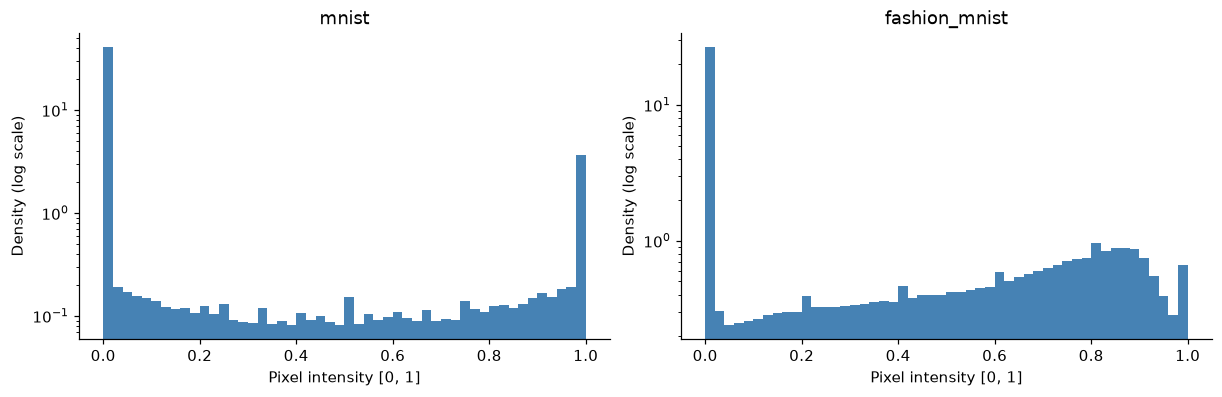

,sample_images,min,max,mean,std,zero_pixels_fraction
dataset,,,,,,
mnist,5000,0.0,1.0,0.1298,0.3073,0.8103
fashion_mnist,5000,0.0,1.0,0.2822,0.3510,0.5059


In [8]:
pixel_rows = []
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), constrained_layout=True)
rng = np.random.default_rng(SEED)
for ax, (name, dataset) in zip(axes, datasets.items()):
    indices = rng.choice(splits[name]["train_idx"], size=5000, replace=False)
    pixels = dataset.data[torch.from_numpy(indices)].numpy().astype(np.float32) / 255.0
    pixel_rows.append({"dataset": name, "sample_images": len(indices),
                       "min": float(pixels.min()), "max": float(pixels.max()),
                       "mean": float(pixels.mean()), "std": float(pixels.std()),
                       "zero_pixels_fraction": float((pixels == 0).mean())})
    ax.hist(pixels.ravel(), bins=50, range=(0, 1), density=True, color="steelblue")
    ax.set(title=name, xlabel="Pixel intensity [0, 1]", ylabel="Density (log scale)")
    ax.set_yscale("log")
show_figure(fig, "pixel_distributions.png")
pixel_summary = pd.DataFrame(pixel_rows).set_index("dataset")
display(pixel_summary.round(4))
if SAVE_RESULTS:
    pixel_summary.to_csv(METRIC_DIR / "pixel_summary.csv")


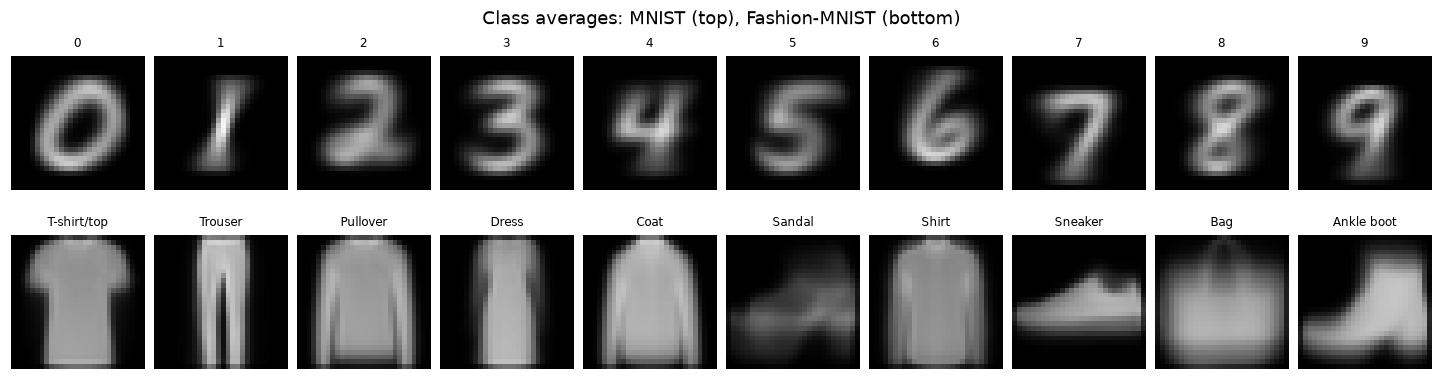

In [9]:
fig, axes = plt.subplots(2, 10, figsize=(13, 3.5), constrained_layout=True)
for row, (name, dataset) in enumerate(datasets.items()):
    train_idx = splits[name]["train_idx"]
    labels = dataset.targets.numpy()
    for label in range(10):
        indices = train_idx[labels[train_idx] == label]
        mean_image = dataset.data[torch.from_numpy(indices)].float().mean(dim=0) / 255.0
        axes[row, label].imshow(mean_image.numpy(), cmap="gray", vmin=0, vmax=1)
        axes[row, label].set_title(class_names[name][label], fontsize=8)
        axes[row, label].axis("off")
fig.suptitle("Class averages: MNIST (top), Fashion-MNIST (bottom)")
show_figure(fig, "class_average_images.png")


## 6. Inputs for the two models

The VAE will receive values in $[0,1]$, matching its sigmoid output and initial binary cross-entropy reconstruction objective. Using BCE on grayscale targets is a modeling choice, not a claim that the images are binary.

For diffusion, the same pixels are mapped to $[-1,1]$ before adding Gaussian noise. Noisy inputs can go outside that interval. These values should not be clipped during training.


In [10]:
normalization_rows = []
for name, dataset in datasets.items():
    idx = int(example_indices[name][0, 0])
    raw = dataset.data[idx]
    x_vae = raw.float().unsqueeze(0).unsqueeze(0) / 255.0
    x_diffusion = 2.0 * x_vae - 1.0
    assert x_vae.shape == (1, 1, 28, 28)
    assert torch.allclose((x_diffusion + 1.0) / 2.0, x_vae, atol=1e-7)
    normalization_rows.append({"dataset": name, "batch_shape": tuple(x_vae.shape),
                               "VAE_min": x_vae.min().item(), "VAE_max": x_vae.max().item(),
                               "diffusion_min": x_diffusion.min().item(),
                               "diffusion_max": x_diffusion.max().item()})
display(pd.DataFrame(normalization_rows).set_index("dataset"))


,batch_shape,VAE_min,VAE_max,diffusion_min,diffusion_max
dataset,,,,,
mnist,"(1, 1, 28, 28)",0.0,1.0,-1.0,1.0
fashion_mnist,"(1, 1, 28, 28)",0.0,1.0,-1.0,1.0


## 7. The forward diffusion process

A DDPM gradually adds Gaussian noise. A noisy image can be sampled directly at a chosen timestep:

$$x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon,
\qquad \epsilon \sim \mathcal{N}(0,I),$$

where $\alpha_t = 1-\beta_t$ and $\bar\alpha_t = \prod_{s=1}^{t}\alpha_s$.

This illustration uses 1,000 steps with a linear noise schedule. Step 0 is the clean image, so $\bar\alpha_0=1$. These are starting settings for understanding the process, not tuned training parameters.


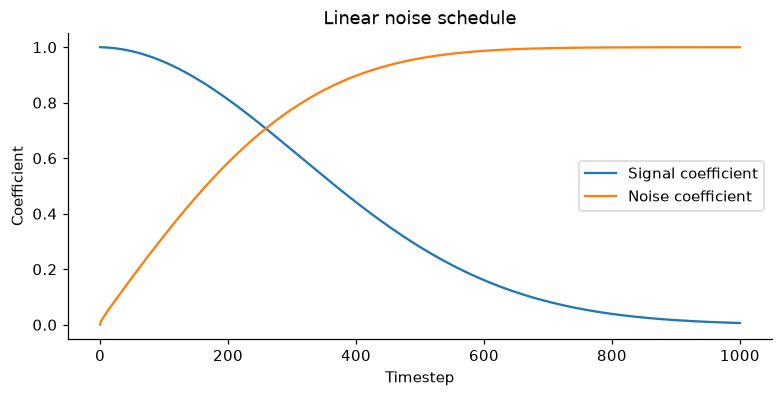

In [ ]:
T = 1000
betas = torch.linspace(1e-4, 0.02, T)
alphas = 1.0 - betas
alpha_bar = torch.cat([torch.ones(1), torch.cumprod(alphas, dim=0)])

assert alpha_bar.shape == (T + 1,)
assert alpha_bar[0].item() == 1.0
assert torch.all(alpha_bar[1:] < alpha_bar[:-1])

def add_noise(x0, timestep, noise):
    # timestep is an integer between 0 (clean) and T.
    if not 0 <= timestep <= T:
        raise ValueError(f"timestep must lie between 0 and {T}")
    a = alpha_bar[timestep].to(device=x0.device, dtype=x0.dtype)
    return a.sqrt() * x0 + (1.0 - a).sqrt() * noise

fig, ax = plt.subplots(figsize=(7, 3.5), constrained_layout=True)
steps = np.arange(T + 1)
ax.plot(steps, alpha_bar.sqrt().numpy(), label="Signal coefficient")
ax.plot(steps, (1 - alpha_bar).sqrt().numpy(), label="Noise coefficient")
ax.set(xlabel="Timestep", ylabel="Coefficient", title="Linear noise schedule")
ax.legend()
show_figure(fig, "diffusion_coefficients.png")


The next grid reuses one noise tensor across timesteps for each image, making the change in signal strength easier to see. Each column follows the correct marginal distribution, but this is **not a single simulated Markov trajectory**.

Only the displayed images are clipped. The underlying noisy tensors are unchanged. This is the forward process; learned denoising and generation come later.


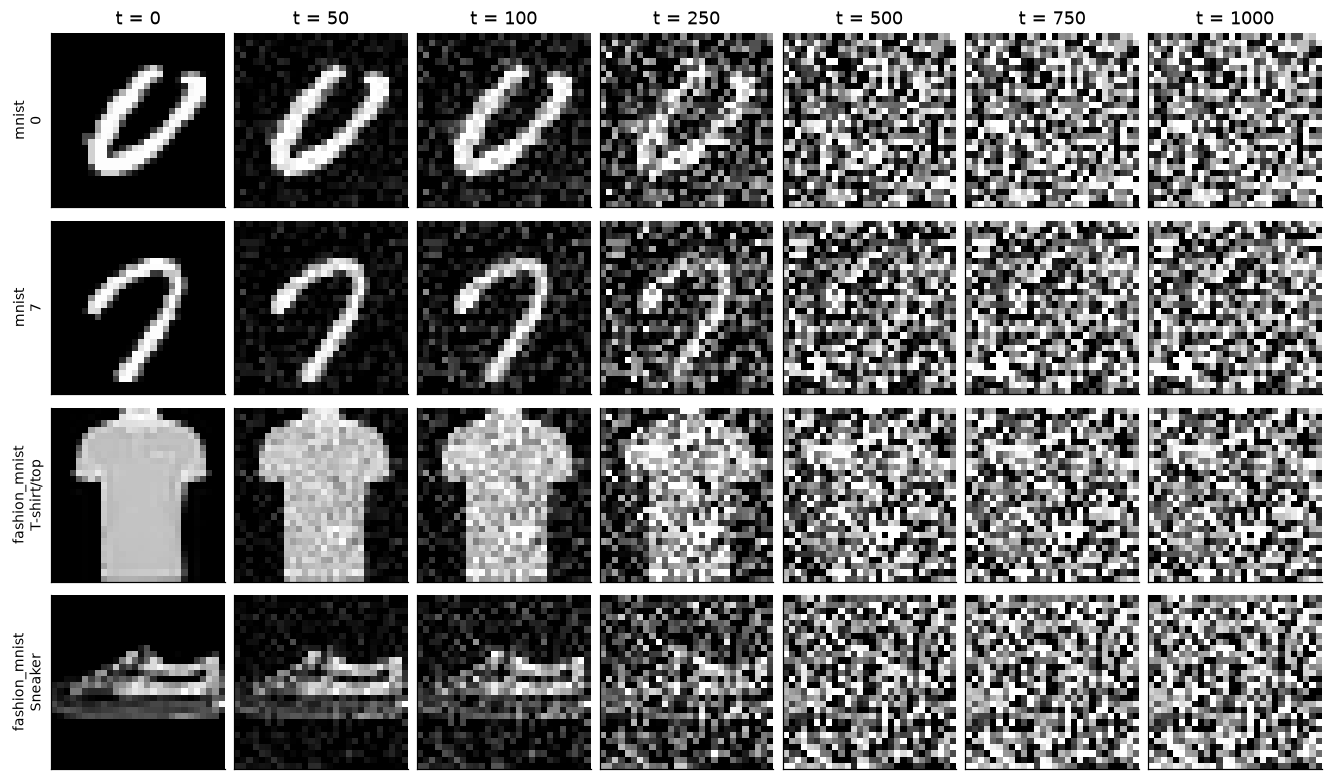

,dataset,label,training_index,timestep,min,max,mean,std
0,mnist,0,1346,0,-1.000,1.000,-0.683,0.669
6,mnist,0,1346,1000,-2.829,2.708,0.017,1.000
7,mnist,7,50375,0,-1.000,1.000,-0.783,0.560
13,mnist,7,50375,1000,-2.984,3.251,-0.034,1.014
14,fashion_mnist,0,33152,0,-1.000,1.000,-0.189,0.757
20,fashion_mnist,0,33152,1000,-3.169,3.317,0.009,0.980
21,fashion_mnist,7,54750,0,-1.000,0.992,-0.763,0.454
27,fashion_mnist,7,54750,1000,-3.183,3.449,0.030,0.993


In [ ]:
timesteps = [0, 50, 100, 250, 500, 750, 1000]
noise_generator = torch.Generator().manual_seed(SEED)
fig, axes = plt.subplots(4, len(timesteps), figsize=(12, 7), constrained_layout=True)
noise_rows = []
row = 0
for name, dataset in datasets.items():
    # Two reproducible training examples per dataset.
    for label in [0, 7]:
        idx = int(example_indices[name][label, 0])
        x0 = 2.0 * dataset.data[idx].float() / 255.0 - 1.0
        epsilon = torch.randn(x0.shape, generator=noise_generator)
        assert torch.allclose(add_noise(x0, 0, epsilon), x0)
        for col, t in enumerate(timesteps):
            xt = add_noise(x0, t, epsilon)
            visible = ((xt + 1.0) / 2.0).clamp(0, 1)
            axes[row, col].imshow(visible.numpy(), cmap="gray", vmin=0, vmax=1)
            axes[row, col].set_xticks([])
            axes[row, col].set_yticks([])
            if row == 0:
                axes[row, col].set_title(f"t = {t}")
            if col == 0:
                axes[row, col].set_ylabel(f"{name}\n{class_names[name][label]}", fontsize=9)
            noise_rows.append({"dataset": name, "label": label, "training_index": idx,
                               "timestep": t, "min": xt.min().item(), "max": xt.max().item(),
                               "mean": xt.mean().item(), "std": xt.std().item()})
        row += 1
show_figure(fig, "forward_diffusion_examples.png")
noise_summary = pd.DataFrame(noise_rows)
display(noise_summary[noise_summary["timestep"].isin([0, 1000])].round(3))
if SAVE_RESULTS:
    noise_summary.to_csv(METRIC_DIR / "forward_diffusion_summary.csv", index=False)




Figures and tables from this notebook are saved under `results/figures/` and `results/metrics/` when `SAVE_RESULTS=True`.

### References

- [MNIST in torchvision](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html)
- [Fashion-MNIST dataset](https://github.com/zalandoresearch/fashion-mnist)
- [Ho et al., Denoising Diffusion Probabilistic Models](https://arxiv.org/abs/2006.11239)
